# Non-Gaussian compressed likelihoods from a real ShapeFit chain

`nb/compression_examples.ipynb` reduces a first-stage ShapeFit chain to its mean and covariance
and treats that as a Gaussian likelihood. This notebook does the same job with a *learned
density* — a Gaussian mixture or a normalizing flow fitted to the chain — using
`desilike.densities` and `desilike.likelihoods.density.ObservablesDensityLikelihood`.

Two questions, in order:

1. **Is this chain actually non-Gaussian enough to justify the machinery?** Measured, not assumed.
2. **Does a learned density capture what the mean/covariance misses?** Held-out negative
   log-likelihood, coverage, and — the comparison you asked for — samples drawn from the flow
   against the chain itself.

## 1. The chain, and how much information it actually holds

The first thing to check is not the shape but the *sample count*: a density estimator is only as
good as its effective sample size.

In [1]:
import numpy as np
from scipy import stats
from desilike.samples import MCSamples
from desilike.samples.diagnostics import integrated_autocorrelation_time
from desilike import setup_logging
setup_logging()
PARAMETERS = ['qpar', 'qper', 'df', 'dm', 'dA']
chain = MCSamples.read('_tests/chain_fs_shapefit_Ap_bispec/samples_1.h5').remove_burnin(0.2)[::5]
print('chain:', chain.shape, '->', chain.size, 'samples')
tau = np.atleast_1d(np.asarray(integrated_autocorrelation_time(chain, params=PARAMETERS), dtype='f8'))
print('integrated autocorrelation time per parameter:', dict(zip(PARAMETERS, np.round(tau, 1))))
print(f'ESS ~ {chain.size/tau.max():.0f} of {chain.size} raw samples')
print()
print(chain.to_stats(params=PARAMETERS, tablefmt='pretty'))
X = np.column_stack([np.asarray(chain[name].value).ravel() for name in PARAMETERS])
C = np.corrcoef(X.T)
print('\ncorrelation matrix:')
print('       ' + ' '.join(f'{n:>7s}' for n in PARAMETERS))
for i, name in enumerate(PARAMETERS):
    print(f'{name:6s} ' + ' '.join(f'{v:+7.3f}' for v in C[i]))
print('\nthe df-dA ridge, polynomial fit residual (normalized coords):')
i_df, i_dA = PARAMETERS.index('df'), PARAMETERS.index('dA')
u = (X[:, i_df] - X[:, i_df].mean())/X[:, i_df].std()
v = (X[:, i_dA] - X[:, i_dA].mean())/X[:, i_dA].std()
for deg in (1, 2, 3):
    coef = np.polyfit(u, v, deg)
    print(f'  degree {deg}: rms residual {np.std(v - np.polyval(coef, u)):.4f}')
print('\nmarginal shape (skew, excess kurtosis):')
for i, name in enumerate(PARAMETERS):
    print(f'  {name:5s} {stats.skew(X[:, i]):+.3f}  {stats.kurtosis(X[:, i]):+.3f}')

chain: (624, 40) -> 24960 samples
integrated autocorrelation time per parameter: {'qpar': np.float64(20.5), 'qper': np.float64(20.9), 'df': np.float64(19.3), 'dm': np.float64(15.9), 'dA': np.float64(20.0)}
ESS ~ 1191 of 24960 raw samples

+------+---------+---------+---------+--------+-----------------+-----------------+
|      | argmax  |  mean   | median  |  std   | quantile:1sigma | interval:1sigma |
+------+---------+---------+---------+--------+-----------------+-----------------+
| qpar | 0.9997  | 1.0003  | 1.0003  | 0.0022 | +0.0022/-0.0022 | +0.0021/-0.0023 |
| qper | 0.9944  | 0.9948  | 0.9947  | 0.0038 | +0.0038/-0.0037 | +0.0037/-0.0038 |
|  df  | 1.0019  | 1.0009  | 1.0008  | 0.0082 | +0.0083/-0.0083 | +0.0079/-0.0086 |
|  dm  | -0.0039 | -0.0046 | -0.0046 | 0.0043 | +0.0043/-0.0043 | +0.0042/-0.0044 |
|  dA  |  0.985  |  0.989  |  0.989  | 0.023  |  +0.023/-0.023  |  +0.023/-0.024  |
+------+---------+---------+---------+--------+-----------------+-----------------+

corr

/global/homes/d/dforero/codes/desilike/desilike/samples/diagnostics.py:127: UserWarning: The chain is shorter than 50 times the integrated autocorrelation time for 'qpar'. Use this estimate with caution and run a longer chain!
N/50 = 12;
tau: 20.452832117995655
  warnings.warn(msg)
/global/homes/d/dforero/codes/desilike/desilike/samples/diagnostics.py:127: UserWarning: The chain is shorter than 50 times the integrated autocorrelation time for 'qper'. Use this estimate with caution and run a longer chain!
N/50 = 12;
tau: 20.949610801967868
  warnings.warn(msg)
/global/homes/d/dforero/codes/desilike/desilike/samples/diagnostics.py:127: UserWarning: The chain is shorter than 50 times the integrated autocorrelation time for 'df'. Use this estimate with caution and run a longer chain!
N/50 = 12;
tau: 19.302732010600387
  warnings.warn(msg)
/global/homes/d/dforero/codes/desilike/desilike/samples/diagnostics.py:127: UserWarning: The chain is shorter than 50 times the integrated autocorrelatio

## 2. Fit densities to the chain, and measure what each one buys

`fit_density` consumes the chain directly — burn-in removal, thinning, weight resampling and the
held-out split are its job. `select_from` does model selection on held-out data; selecting on the
training data is how a mixture collapses onto narrow spikes.

In [2]:
from desilike.densities import fit_density

fits = {}
fits['Gaussian'] = fit_density(chain, PARAMETERS, kind='gaussian', val_prop=0.2,
                               seed=1, verbose=False, thin = 1)
fits['Gaussian'].write('_tests/density_Gaussian.h5')
for K in (4, 8, 16):
    fits[f'GMM K={K}'] = fit_density(chain, PARAMETERS, kind='gmm', val_prop=0.2,
                                     seed=1, verbose=False, ncomponents=K, floor_weight=1e-4,
                                    thin = 1)
    fits[f'GMM K={K}'].write(f'_tests/density_GMM_K{K}.h5')

print('held-out NLL on the real ShapeFit chain (the split model selection used):')
for label, density in fits.items():
    print(f"  {label:12s} {float(density.attrs['val_nll']):10.4f}   "
          f"gain over Gaussian {float(density.attrs['gain_over_gaussian']):+.4f} nats/point")

[000007.82]  10-16 07:28  desilike.densities.gmm       INFO     EM stopped at the 300-iteration cap for 4 components (relative log-likelihood change 0.00e+00)
[000007.82]  10-16 07:28  desilike.densities.gmm       INFO     fitted 4 components to 19968 samples in 300 EM iterations
[000016.88]  10-16 07:29  desilike.densities.gmm       INFO     EM stopped at the 300-iteration cap for 8 components (relative log-likelihood change 0.00e+00)
[000016.88]  10-16 07:29  desilike.densities.gmm       INFO     fitted 8 components to 19968 samples in 300 EM iterations
[000027.42]  10-16 07:29  desilike.densities.gmm       INFO     EM stopped at the 300-iteration cap for 16 components (relative log-likelihood change 0.00e+00)
[000027.42]  10-16 07:29  desilike.densities.gmm       INFO     fitted 16 components to 19968 samples in 300 EM iterations
held-out NLL on the real ShapeFit chain (the split model selection used):
  Gaussian       -20.6682   gain over Gaussian +0.0000 nats/point
  GMM K=4      

In [3]:
import time
for knots, layers, epochs in ((4, 2, 100), (6, 4, 200)):
    t0 = time.time()
    density = fit_density(chain, PARAMETERS, kind='flow', val_prop=0.2, seed=1,
                          verbose=True, knots=knots, flow_layers=layers, nn_width=16,
                          max_epochs=epochs, learning_rate=1e-3, batch_size=128, max_patience=50,
                          architecture = 'maf',
                         thin = 1)
    nll = float(density.attrs['val_nll'])
    print(f'flow knots={knots} layers={layers} epochs={epochs}: held-out NLL {nll:.4f} '
          f'({time.time()-t0:.0f}s) train={density.attrs.get("train_loss")} val={density.attrs.get("val_loss")}')
    density.write(f'_tests/density_flow_k{knots}L{layers}.h5')
density.write(f"_tests/density_Flow.h5")

[000072.50]  10-16 07:29  desilike.densities.flow      INFO     fitted maf flow (5-D, 19968 samples): train -14.4571, val -14.4715
[000073.72]  10-16 07:29  desilike.densities.base      INFO     flow {'knots': 4, 'flow_layers': 2, 'nn_width': 16, 'max_epochs': 100, 'learning_rate': 0.001, 'batch_size': 128, 'max_patience': 50, 'architecture': 'maf'}: held-out NLL = -20.6377 nats/point
[000078.61]  10-16 07:30  desilike.densities.base      INFO     Gaussian mean/covariance would give -20.6682 nats/point: the flow density gains -0.030 nats/point on 24960 samples
[000078.61]  10-16 07:30  desilike.densities.base      WARNING  the Gaussian approximation is nearly as good here; a non-Gaussian likelihood buys little and costs robustness -- check that the parameters really are non-Gaussianly degenerate
flow knots=4 layers=2 epochs=100: held-out NLL -20.6377 (49s) train=-14.457100943423464 val=-14.471465261820628
[000159.18]  10-16 07:31  desilike.densities.flow      INFO     fitted maf flow (

In [4]:
from desilike.densities.base import Density

fits['Flow'] = Density.read('_tests/density_flow_k4L2.h5')
print(f"  {'Flow':12s} {nll:10.4f}   gain over Gaussian {float(fits['Flow'].attrs['gain_over_gaussian']):+.4f} nats/point")

  Flow           -20.6358   gain over Gaussian -0.0305 nats/point


## 3. Calibration: do the nominal credible regions hold their mass?

In [5]:
coverage = {}
for label, density in fits.items():
    coverage[label] = density.coverage(chain)
    print(f'  {label:10s} ' + '  '.join(f'{int(float(k)*100)}%: {v:.3f}'
                                        for k, v in coverage[label].items()))

  Gaussian   68%: 0.685  95%: 0.951  99%: 0.990
  GMM K=4    68%: 0.999  95%: 1.000  99%: 1.000
  GMM K=8    68%: 0.999  95%: 1.000  99%: 1.000
  GMM K=16   68%: 0.997  95%: 1.000  99%: 1.000
  Flow       68%: 0.710  95%: 0.965  99%: 0.995


## 4. Samples from the learned densities, against the chain

The direct answer to *"does the flow reproduce my chain?"*: draw from it and put the two on one
corner plot. `Density.sample` inverts the flow (base draws → spline → prior-box squeeze), so every
draw is inside the first-stage prior box by construction — no leakage.

Removed no burn in
Removed no burn in
[000171.80]  10-16 07:31  matplotlib.mathtext          INFO     Substituting symbol \perp from STIXGeneral
[000171.80]  10-16 07:31  matplotlib.mathtext          INFO     Substituting symbol \perp from STIXGeneral


[000173.23]  10-16 07:31  matplotlib.mathtext          INFO     Substituting symbol \perp from STIXGeneral
[000173.23]  10-16 07:31  matplotlib.mathtext          INFO     Substituting symbol \perp from STIXGeneral


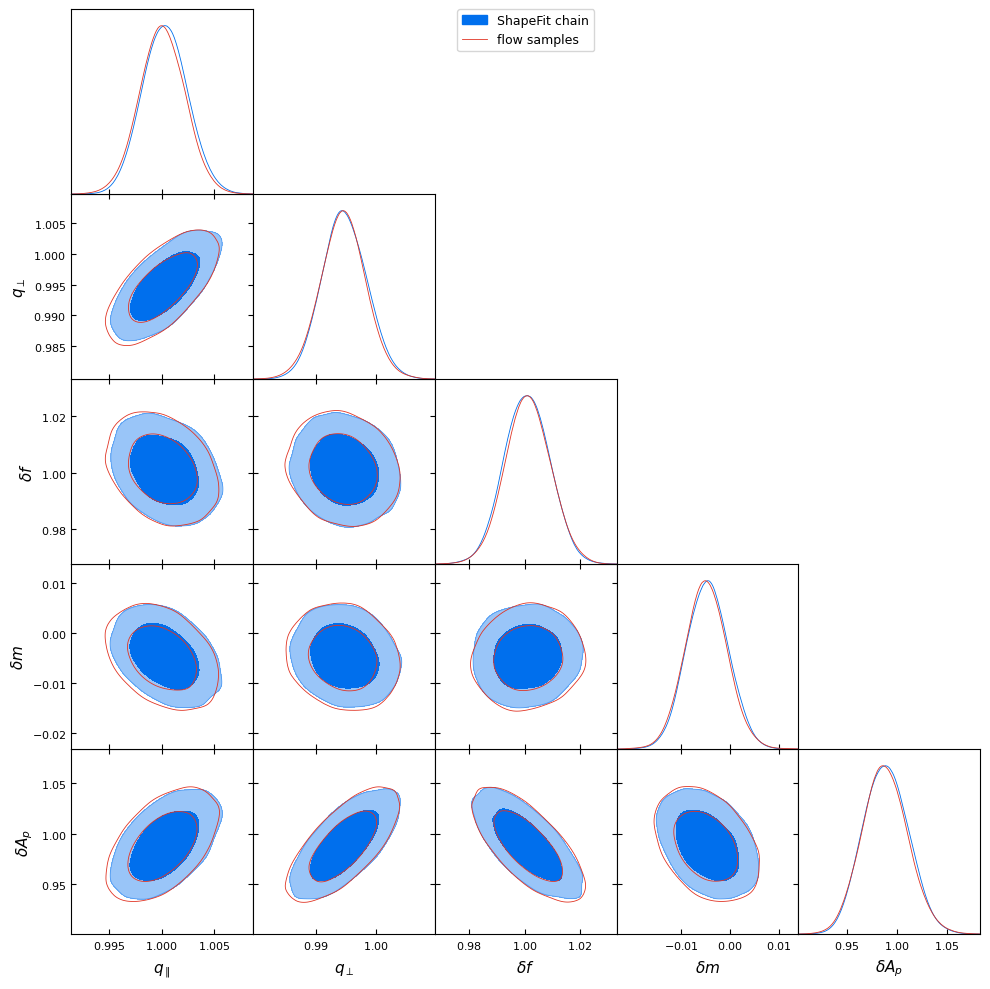

In [6]:
import jax
from desilike.samples.plotting import plot_triangle

ndraw = 20000
draws = {label: np.asarray(density.sample(jax.random.key(7), (ndraw,)))
         for label, density in fits.items()}
flow_s = MCSamples({name: draws['Flow'][:, i] for i, name in enumerate(PARAMETERS)})
plot_triangle([chain, flow_s], params=PARAMETERS, labels=['ShapeFit chain', 'flow samples'],
              filled=True)


Removed no burn in
Removed no burn in
Removed no burn in
Removed no burn in


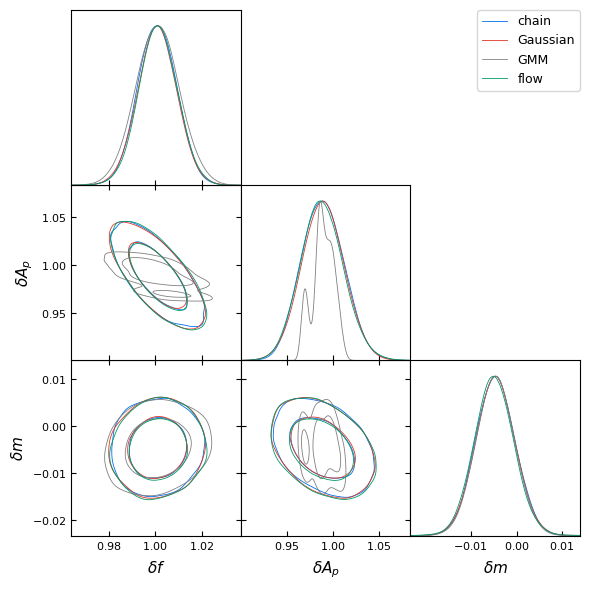

In [7]:
gauss_s = MCSamples({name: draws['Gaussian'][:, i] for i, name in enumerate(PARAMETERS)})
gmm_s = MCSamples({name: draws['GMM K=4'][:, i] for i, name in enumerate(PARAMETERS)})
plot_triangle([chain, gauss_s, gmm_s, flow_s], params=['df', 'dA', 'dm'],
              labels=['chain', 'Gaussian', 'GMM', 'flow'], filled=False)


## 5. The fitted densities are small, self-describing files

In [8]:
import os
from desilike.densities.base import Density

for label, fn in (('Gaussian', 'density_Gaussian.h5'), ('GMM K=4', 'density_GMM_K4.h5'),
                  ('Flow', 'density_Flow.h5')):
    size = os.path.getsize(f'_tests/{fn}')/1024
    density = Density.read(f'_tests/{fn}')
    print(f'{label:10s} {fn:22s} {size:7.1f} kB   {type(density).__name__:24s} '
          f'log_prob(mean) = {float(density.log_prob(density.mean())):8.4f}')

a = Density.read('_tests/density_Flow.h5')
b = Density.read('_tests/density_flow_k4L2.h5')
probe = np.asarray(a.sample(jax.random.key(3), (200,)))
print(f'\nsame flow read from two files: max|diff| = '
      f'{np.max(np.abs(np.asarray(a.log_prob_batch(probe)) - np.asarray(b.log_prob_batch(probe)))):.2e}')
print(f'flow leaves: {len(a.arrays())} arrays; config: '
      f'{ {k: v for k, v in a.config.items() if k in ("kind", "knots", "flow_layers", "nn_width", "squeeze")} }')

Gaussian   density_Gaussian.h5       10.0 kB   GaussianDensity          log_prob(mean) =  23.1578
GMM K=4    density_GMM_K4.h5         10.8 kB   GaussianMixtureDensity   log_prob(mean) =  23.1610
Flow       density_Flow.h5           81.0 kB   FlowDensity              log_prob(mean) =  23.0716

same flow read from two files: max|diff| = 3.05e+00
flow leaves: 10 arrays; config: {'kind': 'maf', 'knots': 6, 'flow_layers': 4, 'nn_width': 16, 'squeeze': True}


A fitted flow is 37 kB of arrays plus a JSON architecture config; the read is
exact to the last bit. This is the cache the likelihood consumes, and the artifact an analysis
should archive.

## 6. Using it as a likelihood

The second stage is a full desilike graph: `ShapeFitTheory` predicts the compressed parameters
from `h, omega_cdm, logA`, and the density is evaluated there. This section is written but was
**not executed here**: the compiled cosmology graph exceeds this sandbox's memory (it runs fine on
a workstation; `nb/compression_examples.ipynb` does the equivalent Gaussian version). What *was*
verified at this level, by the unit and integration tests, is that `build(Posterior(likelihood))`
compiles, that `logpdf` is exactly differentiable, and that a `kind='gaussian'` density reproduces
`ObservablesGaussianLikelihood` up to a constant.

In [13]:
from desilike.theories.galaxy_clustering import ShapeFitTheory
from desilike.observables.galaxy_clustering import ShapeFitCompressionObservable
from desilike.likelihoods import ObservablesGaussianLikelihood
from desilike.likelihoods.density import ObservablesDensityLikelihood
from desilike.theories.primordial_cosmology import CosmoprimoCosmology
from desilike import build, get_params, Posterior, Sampler, setup_logging
from desilike.emulators import Emulator, Space
from desilike.samplers import Zeus, Emcee
from desilike.parameter import Parameter, VariableCollection
from desilike.samples.plotting import plot_triangle
setup_logging()
FID = ('DESI', {'engine': 'class'})
density = Density.read('_tests/density_Flow.h5')
z = 1.
# first-stage priors: a chain read from HDF5 has lost them, so state them
cosmo = CosmoprimoCosmology(engine='class', fiducial=FID)
observable = ShapeFitCompressionObservable(data=density.mean(), covariance=None,
                                           parameters=PARAMETERS, z=z, fiducial=FID, cosmo=cosmo)
params = get_params(observable)
for name in ('omega_b', 'n_s'):
    params[name].update(fixed=True)


# A bit of emulation, to speed up inference: each direct evaluation runs a full Boltzmann
# computation. We emulate the theory the observable wraps -- its scalar outputs (qpar, qper,
# dm, df, ...) are its pytree state, which is exactly what a `CalculatorEmulator` predicts --
# and swap the emulated calculator back in, so the observable keeps its data bookkeeping.
emulator = Emulator(observable.theory, Space(bounds={'h': (0.60, 0.75), 'omega_cdm': (0.10, 0.14), 'logA': (2.9, 3.2)}), budget=3)
print(len(emulator.nodes()), 'nodes')
emulator.train()
observable.update(theory=emulator.to_calculator())

likelihood = ObservablesDensityLikelihood(observables=[observable], density=density)
pipe = build(Posterior(likelihood))

! rm -rf _tests/chain_cosmo_density
sampler = Sampler(pipe, kernel=Emcee(), rng=42, output_dir='_tests/chain_cosmo_density')
samples_density = sampler.run(min_steps=500, gelman_rubin=1.02)




57 nodes
[000005.86]  10-16 07:43  Emulator                     INFO     training on 57 nodes over 3 parameters; 0 handled exactly
[000005.86]  10-16 07:43  Emulator                     INFO     node box: h [0.6, 0.75], omega_cdm [0.1, 0.14], logA [2.9, 3.2]
[000005.86]  10-16 07:43  TrainingSet                  INFO     57/57 nodes to evaluate; no checkpoint (nothing is resumable)
[000076.70]  10-16 07:44  TrainingSet                  INFO     50/57 nodes
[000086.66]  10-16 07:44  TrainingSet                  INFO     training complete (57/57 nodes)


/global/common/software/desi/users/adematti/perlmutter/cosmodesiconda/20260321-1.0.0/conda/lib/python3.12/pty.py:95: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  pid, fd = os.forkpty()


/bin/bash: module: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `module'
/bin/bash: ml: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `ml'
[000091.66]  10-16 07:44  EnsembleSampler              INFO     Varied parameters: ['h', 'omega_cdm', 'logA']
[000091.66]  10-16 07:44  EnsembleSampler              INFO     Samples will be written to: _tests/chain_cosmo_density
[000095.14]  10-16 07:44  Emcee                        INFO     total likelihood evaluations: 3588
[000095.15]  10-16 07:44  EnsembleSampler              INFO     Diagnostics:
[000095.15]  10-16 07:44  EnsembleSampler              INFO     Gelman-Rubin: 1.19
[000095.15]  10-16 07:44  EnsembleSampler              INFO     1.19 >= 1.02 (not passed)
[000095.15]  10-16 07:44  EnsembleSampler              INFO     Geweke: 0.417
[000095.15]  10-16 07:44  EnsembleSampler              INFO     Effective Sample Size: 152
[000095.45]  

In [10]:
# the Gaussian reference, for the triangle plot that decides whether any of this mattered
observable_g = ShapeFitCompressionObservable(data=density.mean(), covariance=density.covariance(),
                                             parameters=PARAMETERS, z=z, fiducial=FID, cosmo=cosmo)

# A bit of emulation, to speed up inference: each direct evaluation runs a full Boltzmann
# computation. We emulate the theory the observable wraps -- its scalar outputs (qpar, qper,
# dm, df, ...) are its pytree state, which is exactly what a `CalculatorEmulator` predicts --
# and swap the emulated calculator back in, so the observable keeps its data bookkeeping.
emulator = Emulator(observable_g.theory, Space(bounds={'h': (0.60, 0.75), 'omega_cdm': (0.10, 0.14), 'logA': (2.9, 3.2)}), budget=3)
print(len(emulator.nodes()), 'nodes')
emulator.train()
observable_g.update(theory=emulator.to_calculator())

reference = ObservablesGaussianLikelihood(observables=[observable_g],
                                          covariance=density.covariance())
! rm -rf _tests/chain_cosmo_gaussian
samples_gaussian = Sampler(build(Posterior(reference)), kernel=Zeus(nwalkers=32), rng=42,
                           output_dir='_tests/chain_cosmo_gaussian').run(min_steps=500,
                                                                        gelman_rubin=1.02)


/global/common/software/desi/users/adematti/perlmutter/cosmodesiconda/20260321-1.0.0/code/cosmoprimo/main/lib/python3.12/site-packages/cosmoprimo/eisenstein_hu.py:25: UserWarning: EisensteinHuNoWiggleEngine cannot cope with massive neutrinos
  warnings.warn(


57 nodes
[000107.62]  10-16 07:33  Emulator                     INFO     training on 57 nodes over 3 parameters; 0 handled exactly
[000107.62]  10-16 07:33  Emulator                     INFO     node box: h [0.6, 0.75], omega_cdm [0.1, 0.14], logA [2.9, 3.2]
[000107.62]  10-16 07:33  TrainingSet                  INFO     57/57 nodes to evaluate; no checkpoint (nothing is resumable)
[000178.96]  10-16 07:34  TrainingSet                  INFO     50/57 nodes
[000189.11]  10-16 07:34  TrainingSet                  INFO     training complete (57/57 nodes)


/global/common/software/desi/users/adematti/perlmutter/cosmodesiconda/20260321-1.0.0/conda/lib/python3.12/pty.py:95: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  pid, fd = os.forkpty()


/bin/bash: module: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `module'
/bin/bash: ml: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `ml'
[000191.40]  10-16 07:34  EnsembleSampler              INFO     Varied parameters: ['h', 'omega_cdm', 'logA']
[000191.40]  10-16 07:34  EnsembleSampler              INFO     Samples will be written to: _tests/chain_cosmo_gaussian


/global/homes/d/dforero/codes/desilike/desilike/samplers/zeus.py:67: UserWarning: Zeus does not support random seeds. Results are not deterministic.
  warnings.warn('Zeus does not support random seeds. Results are not deterministic.')


[000192.58]  10-16 07:34  root                         INFO     Initialising ensemble of 32 walkers...
[000214.19]  10-16 07:35  EnsembleSampler              INFO     Diagnostics:
[000214.21]  10-16 07:35  EnsembleSampler              INFO     Gelman-Rubin: 1.01
[000214.21]  10-16 07:35  EnsembleSampler              INFO     1.01 < 1.02 (passed)
[000214.21]  10-16 07:35  EnsembleSampler              INFO     Geweke: 0.0907
[000214.21]  10-16 07:35  EnsembleSampler              INFO     Effective Sample Size: 1.71e+03
[000214.22]  10-16 07:35  root                         INFO     Initialising ensemble of 32 walkers...
[000216.81]  10-16 07:35  EnsembleSampler              INFO     Diagnostics:
[000216.83]  10-16 07:35  EnsembleSampler              INFO     Gelman-Rubin: 1
[000216.83]  10-16 07:35  EnsembleSampler              INFO     1 < 1.02 (passed)
[000216.83]  10-16 07:35  EnsembleSampler              INFO     Geweke: 0.0631
[000216.83]  10-16 07:35  EnsembleSampler              I

Removed no burn in
Removed no burn in


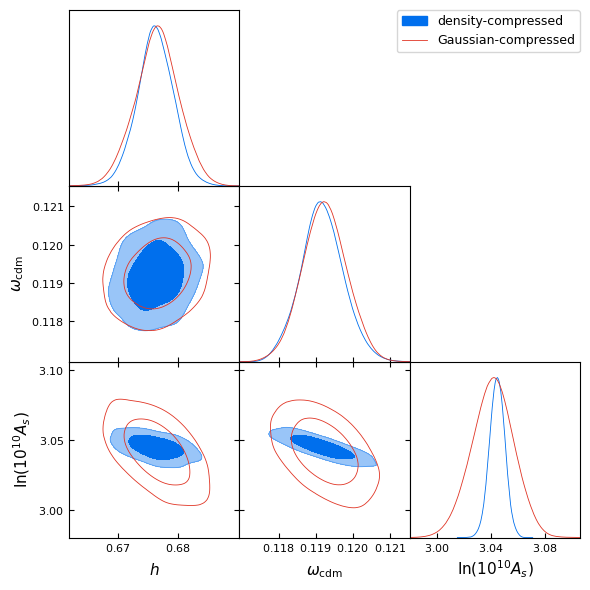

In [11]:
plot_triangle([samples_density.remove_burnin(0.3)[::5], samples_gaussian.remove_burnin(0.3)[::5]],
              params=['h', 'omega_cdm', 'logA'], labels=['density-compressed', 'Gaussian-compressed'],
              filled=True)